# Reweighing with IBM AI Fairness 360 on Adult, German Credit and COMPAS

Uses `aif360.algorithms.preprocessing.Reweighing` (Kamiran & Calders, 2012) and the AIF360 metric classes `BinaryLabelDatasetMetric` / `ClassificationMetric` for DP_Diff (`statistical_parity_difference`), DIR (`disparate_impact`) and `consistency`.

**Pipeline per dataset and seed:** (1) metrics on the original labels of the full dataset; (2) split stratified on label x protected group; (3) `Reweighing` fitted on the training set, its instance weights passed to a logistic regression; (4) all measures on the held-out test set.

Requires `data/adult.data`, `data/german.data`, `data/compas.csv` next to this notebook.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from aif360.datasets import BinaryLabelDataset
from aif360.metrics import BinaryLabelDatasetMetric, ClassificationMetric
from aif360.algorithms.preprocessing import Reweighing

warnings.filterwarnings("ignore")
# avoids a threadpoolctl crash on this machine when AIF360 computes nearest neighbours
sklearn.set_config(enable_cython_pairwise_dist=False)
DATA = os.path.join(os.getcwd(), "data")   # run the notebook from the folder that contains data/


[TensorFlow DLL Diagnostic] Analyzing: C:\Users\zangp\anaconda3\lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd


  File "C:\Users\zangp\anaconda3\lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.: AdversarialDebiasing will be unavailable. To install, run:
pip install 'aif360[AdversarialDebiasing]'


[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.



[TensorFlow DLL Diagnostic] Analyzing: C:\Users\zangp\anaconda3\lib\site-packages\tensorflow\python\_pywrap_tensorflow_internal.pyd


  File "C:\Users\zangp\anaconda3\lib\site-packages\tensorflow\python\pywrap_tensorflow.py", line 74, in <module>
    from tensorflow.python._pywrap_tensorflow_internal import *
ImportError: DLL load failed while importing _pywrap_tensorflow_internal: A dynamic link library (DLL) initialization routine failed.


Failed to load the native TensorFlow runtime.
See https://www.tensorflow.org/install/errors for some common causes and solutions.
If you need help, create an issue at https://github.com/tensorflow/tensorflow/issues and include the entire stack trace above this error message.: AdversarialDebiasing will be unavailable. To install, run:
pip install 'aif360[AdversarialDebiasing]'


pip install 'aif360[Reductions]'


pip install 'aif360[Reductions]'


pip install 'aif360[inFairness]'


pip install 'aif360[Reductions]'


[Error] Failed to load _pywrap_tensorflow_common.dll: INITIALIZATION FAILED (0x45A) - The DLL's DllMain returned false.
    Hint: This often happens if your CPU lacks required instructions (like AVX/AVX2)
    or if the Microsoft Visual C++ Redistributable is outdated/missing.


## Parameter settings

In [2]:
SEEDS = list(range(10))     # 10 random stratified splits, results averaged
TEST_SIZE = 0.30
LR_C = 1.0                  # logistic regression inverse regularisation (L2 penalty)
LR_MAX_ITER = 2000
THRESHOLD = 0.5
K_CONSISTENCY = 5           # neighbours used by AIF360's consistency metric
UNPRIV = [{"s": 0}]         # 's' = protected attribute column, 1 = privileged group
PRIV = [{"s": 1}]

## Datasets
Each loader returns features `X`, label `y` (1 = favourable) and protected attribute `s` (1 = privileged).

In [3]:
def load_adult():
    cols = ["age", "workclass", "fnlwgt", "education", "education-num", "marital-status",
            "occupation", "relationship", "race", "sex", "capital-gain", "capital-loss",
            "hours-per-week", "native-country", "income"]
    df = pd.read_csv(os.path.join(DATA, "adult.data"), names=cols, skipinitialspace=True, na_values="?").dropna()
    y = (df["income"] == ">50K").astype(int)
    s = (df["sex"] == "Male").astype(int)                    # privileged: male
    X = df.drop(columns=["income", "fnlwgt", "education"])
    return X.reset_index(drop=True), y.reset_index(drop=True), s.reset_index(drop=True)


def load_german():
    cols = ["status", "duration", "credit_history", "purpose", "credit_amount", "savings",
            "employment", "installment_rate", "personal_status", "other_debtors",
            "residence_since", "property", "age", "other_installment", "housing",
            "existing_credits", "job", "num_liable", "telephone", "foreign_worker", "credit"]
    df = pd.read_csv(os.path.join(DATA, "german.data"), sep=" ", names=cols)
    y = (df["credit"] == 1).astype(int)                      # 1 = good credit risk
    s = (df["age"] >= 25).astype(int)                        # privileged: age >= 25
    return df.drop(columns=["credit"]).reset_index(drop=True), y.reset_index(drop=True), s.reset_index(drop=True)


def load_compas():
    df = pd.read_csv(os.path.join(DATA, "compas.csv"))
    df = df[(df["days_b_screening_arrest"] <= 30) & (df["days_b_screening_arrest"] >= -30)
            & (df["is_recid"] != -1) & (df["c_charge_degree"] != "O") & (df["score_text"] != "N/A")]
    df = df[df["race"].isin(["African-American", "Caucasian"])]
    y = (df["two_year_recid"] == 0).astype(int)              # 1 = no recidivism (favourable)
    s = (df["race"] == "Caucasian").astype(int)              # privileged: Caucasian
    X = df[["sex", "age", "age_cat", "race", "juv_fel_count", "juv_misd_count",
            "juv_other_count", "priors_count", "c_charge_degree"]]
    return X.reset_index(drop=True), y.reset_index(drop=True), s.reset_index(drop=True)


DATASETS = {"Adult (sex)": load_adult, "German (age)": load_german, "COMPAS (race)": load_compas}

## AIF360 helpers
Features are standardised / one-hot encoded (fitted on the training part only) and wrapped in an AIF360 `BinaryLabelDataset` whose protected attribute is the column `s`. `s` is used only by AIF360 (weights and metrics); the model is trained on the encoded features, which still contain the original sex / age / race column, as before.

In [4]:
def preprocessor(X):
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    return ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])


def to_frame(prep, X, fit=False):
    arr = prep.fit_transform(X) if fit else prep.transform(X)
    return pd.DataFrame(arr, columns=prep.get_feature_names_out())


def to_aif(F, y, s):
    """Wrap a numeric feature frame, labels and protected attribute into an AIF360 BinaryLabelDataset."""
    df = F.reset_index(drop=True).copy()
    df["s"] = np.asarray(s)
    df["y"] = np.asarray(y)
    return BinaryLabelDataset(df=df, label_names=["y"], protected_attribute_names=["s"],
                              favorable_label=1, unfavorable_label=0)


def data_fairness(ds):
    """Fairness measures of the labels stored in an AIF360 dataset (true labels or predictions)."""
    m = BinaryLabelDatasetMetric(ds, unprivileged_groups=UNPRIV, privileged_groups=PRIV)
    return {"DP_Diff": m.statistical_parity_difference(),
            "DIR": m.disparate_impact(),
            "Consistency": float(np.ravel(m.consistency(n_neighbors=K_CONSISTENCY))[0])}


def with_predictions(ds, yhat):
    pred = ds.copy(deepcopy=True)
    pred.labels = np.asarray(yhat, dtype=float).reshape(-1, 1)
    return pred


def make_lr():
    return LogisticRegression(C=LR_C, max_iter=LR_MAX_ITER)

## Run the experiment (10 stratified splits)

In [ ]:
rows = []
for name, loader in DATASETS.items():
    X, y, s = loader()
    print(f"{name}: n={len(X)}, P(y=1)={y.mean():.3f}, P(priv)={s.mean():.3f}")

    # (1) measures on the original labels of the full dataset
    prep_all = preprocessor(X)
    ds_all = to_aif(to_frame(prep_all, X, fit=True), y, s)
    rows.append({"dataset": name, "stage": "Original labels (full data)", "seed": -1, **data_fairness(ds_all)})

    strat = y.astype(str) + "_" + s.astype(str)               # stratify on label x protected group
    for seed in SEEDS:
        Xtr, Xte, ytr, yte, str_, ste = train_test_split(X, y, s, test_size=TEST_SIZE, stratify=strat, random_state=seed)
        prep = preprocessor(Xtr)
        Ftr, Fte = to_frame(prep, Xtr, fit=True), to_frame(prep, Xte)
        train_ds, test_ds = to_aif(Ftr, ytr, str_), to_aif(Fte, yte, ste)

        # (2) AIF360 Reweighing: weights learned on the training set only
        rw = Reweighing(unprivileged_groups=UNPRIV, privileged_groups=PRIV)
        train_rw = rw.fit_transform(train_ds)
        gap = BinaryLabelDatasetMetric(train_rw, unprivileged_groups=UNPRIV, privileged_groups=PRIV).statistical_parity_difference()
        assert abs(gap) < 1e-9, gap                           # weighted training data has zero parity gap

        # (3) baseline and reweighed logistic regression
        base = make_lr().fit(Ftr.values, ytr.values)
        rew = make_lr().fit(Ftr.values, ytr.values, sample_weight=train_rw.instance_weights)

        rows.append({"dataset": name, "stage": "Test true labels", "seed": seed, **data_fairness(test_ds)})
        for stage, model in (("Baseline LR", base), ("Reweighing + LR", rew)):
            yhat = (model.predict_proba(Fte.values)[:, 1] >= THRESHOLD).astype(int)
            pred_ds = with_predictions(test_ds, yhat)
            cm = ClassificationMetric(test_ds, pred_ds, unprivileged_groups=UNPRIV, privileged_groups=PRIV)
            row = data_fairness(pred_ds)
            row.update({"Accuracy": cm.accuracy(), "BalAcc": balanced_accuracy_score(yte, yhat), "F1": f1_score(yte, yhat)})
            rows.append({"dataset": name, "stage": stage, "seed": seed, **row})

res = pd.DataFrame(rows)
res.to_csv("results_raw_aif360.csv", index=False)
metrics = ["DP_Diff", "DIR", "Consistency", "Accuracy", "BalAcc", "F1"]
g = res.groupby(["dataset", "stage"], sort=False)[metrics]
summ = g.mean().join(g.std().add_suffix("_sd"))
summ.to_csv("results_summary_aif360.csv")
display(summ[metrics].round(3))
print("std across seeds:")
display(summ[[m + "_sd" for m in metrics]].round(3))

Adult (sex): n=30162, P(y=1)=0.249, P(priv)=0.676


German (age): n=1000, P(y=1)=0.700, P(priv)=0.851


COMPAS (race): n=5278, P(y=1)=0.530, P(priv)=0.398


DP_Diff    DIR  Consistency  \
dataset       stage                                                      
Adult (sex)   Original labels (full data)   -0.200  0.362        0.839   
              Test true labels              -0.200  0.363        0.836   
              Baseline LR                   -0.192  0.291        0.958   
              Reweighing + LR               -0.092  0.586        0.958   
German (age)  Original labels (full data)   -0.129  0.821        0.746   
              Test true labels              -0.128  0.822        0.732   
              Baseline LR                   -0.145  0.817        0.814   
              Reweighing + LR               -0.121  0.847        0.814   
COMPAS (race) Original labels (full data)   -0.132  0.783        0.658   
              Test true labels              -0.132  0.783        0.666   
              Baseline LR                   -0.283  0.620        0.964   
              Reweighing + LR               -0.014  0.977        0.960   

                                           Accuracy  BalAcc     F1  
dataset       stage                                                 
Adult (sex)   Original labels (full data)       NaN     NaN    NaN  
              Test true labels                  NaN     NaN    NaN  
              Baseline LR                     0.849   0.771  0.670  
              Reweighing + LR                 0.843   0.752  0.644  
German (age)  Original labels (full data)       NaN     NaN    NaN  
              Test true labels                  NaN     NaN    NaN  
              Baseline LR                     0.758   0.676  0.835  
              Reweighing + LR                 0.754   0.670  0.833  
COMPAS (race) Original labels (full data)       NaN     NaN    NaN  
              Test true labels                  NaN     NaN    NaN  
              Baseline LR                     0.674   0.670  0.704  
              Reweighing + LR                 0.665   0.660  0.703

std across seeds:


DP_Diff_sd  DIR_sd  Consistency_sd  \
dataset       stage                                                             
Adult (sex)   Original labels (full data)         NaN     NaN             NaN   
              Test true labels                  0.000   0.000           0.001   
              Baseline LR                       0.008   0.018           0.001   
              Reweighing + LR                   0.011   0.036           0.001   
German (age)  Original labels (full data)         NaN     NaN             NaN   
              Test true labels                  0.000   0.000           0.008   
              Baseline LR                       0.079   0.101           0.018   
              Reweighing + LR                   0.066   0.085           0.018   
COMPAS (race) Original labels (full data)         NaN     NaN             NaN   
              Test true labels                  0.000   0.000           0.010   
              Baseline LR                       0.019   0.020           0.002   
              Reweighing + LR                   0.027   0.046           0.004   

                                           Accuracy_sd  BalAcc_sd  F1_sd  
dataset       stage                                                       
Adult (sex)   Original labels (full data)          NaN        NaN    NaN  
              Test true labels                     NaN        NaN    NaN  
              Baseline LR                        0.003      0.004  0.006  
              Reweighing + LR                    0.002      0.003  0.005  
German (age)  Original labels (full data)          NaN        NaN    NaN  
              Test true labels                     NaN        NaN    NaN  
              Baseline LR                        0.018      0.023  0.014  
              Reweighing + LR                    0.020      0.025  0.014  
COMPAS (race) Original labels (full data)          NaN        NaN    NaN  
              Test true labels                     NaN        NaN    NaN  
              Baseline LR                        0.008      0.007  0.009  
              Reweighing + LR                    0.009      0.009  0.011

## Results in Figures

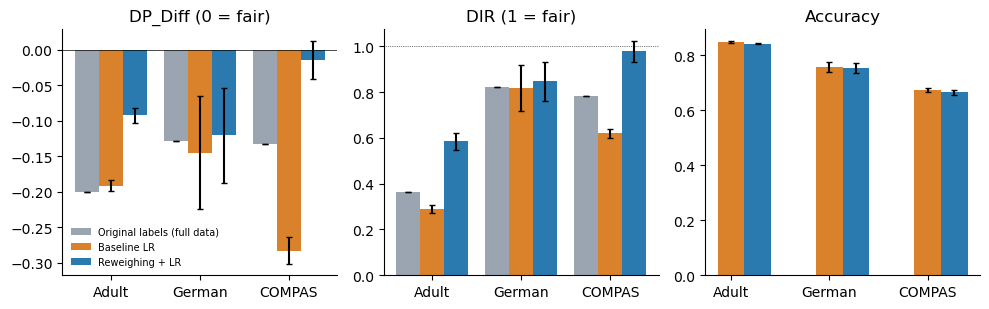

In [ ]:
import matplotlib.pyplot as plt
ds = ["Adult (sex)", "German (age)", "COMPAS (race)"]
cols = {"Original labels (full data)": "#9aa5b1", "Baseline LR": "#d9822b", "Reweighing + LR": "#2a7ab0"}
fig, ax = plt.subplots(1, 3, figsize=(10, 3.2))
for a, (m, t) in zip(ax, [("DP_Diff", "DP_Diff (0 = fair)"), ("DIR", "DIR (1 = fair)"), ("Accuracy", "Accuracy")]):
    for i, (st, c) in enumerate(cols.items()):
        if m == "Accuracy" and st.startswith("Original"):
            continue
        v = [summ.loc[(d, st), m] for d in ds]
        e = [0 if st.startswith("Original") else summ.loc[(d, st), m + "_sd"] for d in ds]
        a.bar([x + (i - 1) * 0.27 for x in range(3)], v, 0.27, yerr=e, color=c, label=st, capsize=2)
    a.set_xticks(range(3)); a.set_xticklabels(["Adult", "German", "COMPAS"]); a.set_title(t)
    for sp in ("top", "right"): a.spines[sp].set_visible(False)
ax[0].axhline(0, color="k", lw=.5); ax[1].axhline(1, color="k", lw=.5, ls=":")
ax[0].legend(fontsize=7, frameon=False, loc="lower left")
plt.tight_layout(); plt.savefig("results_figure_aif360.png", dpi=200); plt.show()